# Egyptian Arabic Automatic Speech Recognition (ASR) Benchmark

A reproducible benchmark comparing six ASR model configurations on a shared sample of the **MGB-3 Egyptian Arabic dataset**.

The goal is to evaluate not only transcription accuracy, but also inference speed and practical reliability. Every model is evaluated against the same selected clips, audio preprocessing, normalization rules, and decoding configuration.

## Models

| Model ID | Model | Backend | Execution environment |
|---|---|---|---|
| `baseline` | Whisper Large-v3 | Whisper | Main notebook environment |
| `qwen` | QwenCleo-ASR | Qwen ASR | Isolated worker environment |
| `turbo` | Whisper-v3-turbo Egyptian code-switching | Whisper | Main notebook environment |
| `egyptalk` | EgypTalk-ASR-v2 | NeMo | Isolated worker environment |
| `dialectal` | Whisper-v3 Arabic Dialectal v2 | Whisper | Main notebook environment |
| `jais` | Jais-ASR | Jais | Isolated worker environment |

## Benchmark design

- **Shared evaluation set:** up to 60 clips selected from the MGB-3 training split.
- **Consistent inputs:** audio is converted to mono, 16 kHz, `float32` before inference.
- **Consistent decoding:** the configured language and generation settings are shared where supported by each backend.
- **Multiple metrics:** raw and normalized WER/CER, real-time factor (RTF), repeated-output loops, and dropped predictions.
- **Resumable execution:** predictions are saved clip by clip, allowing completed work to be reused after a runtime disconnect.

## Why isolated environments?

Some model backends require incompatible dependency versions. QwenCleo-ASR, Jais-ASR, and NeMo therefore run in separate worker environments, while the main notebook environment handles orchestration and the other models. This separation helps avoid dependency conflicts between model implementations.

## Run instructions

1. Open the notebook in Google Colab or a compatible GPU environment.
2. Run sections **1–9** to install dependencies, configure the benchmark, load the data, and initialize the evaluation utilities.
3. Run the individual model cells in section **10**. Models can be run in any order, one at a time.
4. Run sections **11–14** to compare completed runs, inspect visualizations and errors, and export the results.

The first run of an isolated backend may take additional time because its environment and packages are installed.

## Important evaluation caveats

- MGB-3 is public training data. A model may have encountered this dataset during training or fine-tuning; results should not be interpreted as evidence of generalization without checking the model card and evaluating on independent recordings.
- The current configuration evaluates a sample of up to 60 clips, not the full dataset.
- Arabic normalization changes how spelling variants are scored. Both raw and normalized metrics are retained so that the effect is visible.
- Results can vary with GPU hardware, package versions, model revisions, and runtime conditions. Treat comparisons as controlled within this notebook rather than as universal model rankings.


## 1. Install dependencies

Installs the packages required by the main notebook environment for audio handling, model orchestration, evaluation, and Whisper-based models. Qwen, NeMo, and Jais dependencies are installed separately in their isolated environments when those backends are first used.

In [1]:
!pip -q install "transformers>=4.45" "datasets[audio]" jiwer peft accelerate huggingface_hub soundfile scipy pandas tqdm matplotlib

## 2. Configuration

Set the dataset sample size, storage location, decoding options, GPU requirement, rerun behavior, and model specifications here.

The same clip count, random seed, language setting, beam count, and token limit are used across the benchmark where supported. Model-specific options are kept in `MODEL_SPECS`.

In [2]:
# ---- storage ---------------------------------------------------------------
USE_DRIVE = False          # True -> persist outputs on Google Drive (survives Colab disconnects)
OUT_NAME  = "asr_benchmark_outputs"

# ---- data ------------------------------------------------------------------
DATASET = {
    "key": "MGB3",
    "ids": ["severo/Egyptian-ASR-MGB-3", "MightyStudent/Egyptian-ASR-MGB-3"],  # tried in order
    "split": "train",
    "text_col": "sentence",
}
N_CLIPS        = 60
SEED           = 42
SHUFFLE_BUFFER = 500
MIN_AUDIO_SEC  = 0.1

# ---- decoding (identical for every model) ----------------------------------
LANGUAGE       = "ar"
NUM_BEAMS      = 1
MAX_NEW_TOKENS = 225

# ---- run control -----------------------------------------------------------
REQUIRE_GPU     = True
FORCE_RERUN     = False    # True -> ignore cached predictions and redo everything
RERUN_BASELINE  = True     # False -> baseline excluded from the comparison (stored Large-v3 numbers only)
MAX_CONSECUTIVE_ERRORS = 5 # abort a model if it fails this many clips in a row

BASELINE_LABEL      = "Whisper Large-v3 (rerun)"
BASELINE_PREV_LABEL = "Whisper Large-v3"

# ---- models ----------------------------------------------------------------
# "id" is what you pass to bench("<id>") in section 10.
# NOTE: "instruction" is part of the cache key for QwenCleo (kept so earlier predictions are reused).
MODEL_SPECS = [
    {"id": "baseline", "label": BASELINE_LABEL, "repo": "openai/whisper-large-v3",
     "backend": "whisper", "enabled": RERUN_BASELINE, "baseline": True},

    {"id": "qwen", "label": "QwenCleo-ASR", "repo": "mohammedaly22/QwenCleo-ASR",
     "backend": "qwen", "instruction": "Transcribe the audio.", "language_name": "Arabic"},

    {"id": "turbo", "label": "Whisper-v3-turbo Egyptian CS",
     "repo": "mohammedaly22/whisper-large-v3-turbo-egyptian-code-switching",
     "backend": "whisper", "processor_fallback": "openai/whisper-large-v3-turbo"},

    {"id": "egyptalk", "label": "EgypTalk-ASR-v2", "repo": "NAMAA-Space/EgypTalk-ASR-v2",
     "backend": "nemo"},

    {"id": "dialectal", "label": "Whisper-v3 Arabic Dialectal v2",
     "repo": "oddadmix/whisper-large-v3-arabic-dialectal-v2",
     "backend": "whisper", "processor_fallback": "openai/whisper-large-v3"},

    # load_in_4bit=True lowers VRAM (needs bitsandbytes) but changes results; it gets its own cache key.
    {"id": "jais", "label": "Jais-ASR", "repo": "IFM/Jais-ASR",
     "backend": "jais", "load_in_4bit": False},
]
ACTIVE_SPECS = [s for s in MODEL_SPECS if s.get("enabled", True)]
SPEC_BY_ID   = {s["id"]: s for s in MODEL_SPECS}

# ---- isolated environments for backends with conflicting dependencies --------
ENV_PACKAGES = {
    "qwen": ["qwen-asr", "transformers==4.57.6", "accelerate==1.12.0"],
    "jais": ["transformers==5.16.1", "accelerate", "soundfile", "soxr", "bitsandbytes"],
    "nemo": ["nemo_toolkit[asr]"],
}

print("Models:")
for s in MODEL_SPECS:
    print(f"  {s['id']:<10} {s['label']:<34} {s['repo']}  [{s['backend']}]" + ("" if s.get("enabled", True) else "  (disabled)"))

Models:
  baseline   Whisper Large-v3 (rerun)           openai/whisper-large-v3  [whisper]
  qwen       QwenCleo-ASR                       mohammedaly22/QwenCleo-ASR  [qwen]
  turbo      Whisper-v3-turbo Egyptian CS       mohammedaly22/whisper-large-v3-turbo-egyptian-code-switching  [whisper]
  egyptalk   EgypTalk-ASR-v2                    NAMAA-Space/EgypTalk-ASR-v2  [nemo]
  dialectal  Whisper-v3 Arabic Dialectal v2     oddadmix/whisper-large-v3-arabic-dialectal-v2  [whisper]
  jais       Jais-ASR                           IFM/Jais-ASR  [jais]


## 3. Runtime environment and utilities

Initializes the runtime paths and shared helpers used throughout the notebook, including GPU checks, memory cleanup, storage directories, and environment diagnostics.

In [3]:
import os, gc, re, sys, json, time, math, pickle, hashlib, random, warnings, tempfile, shutil, subprocess
from functools import lru_cache
from pathlib import Path
from math import gcd

import numpy as np
import pandas as pd
import torch
import jiwer
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.signal import resample_poly
from datasets import load_dataset
from huggingface_hub import HfApi, hf_hub_download
from IPython.display import display

warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive") / OUT_NAME
else:
    OUT_DIR = Path(OUT_NAME)
PRED_DIR, DATA_DIR, FIG_DIR = OUT_DIR / "predictions", OUT_DIR / "data_cache", OUT_DIR / "figures"
WORKER_DIR, LOG_DIR = OUT_DIR / "workers", OUT_DIR / "logs"
for d in (PRED_DIR, DATA_DIR, FIG_DIR, WORKER_DIR, LOG_DIR): d.mkdir(parents=True, exist_ok=True)

# virtualenvs are big and must be fast -> always on local disk, never on Drive
ENVS_ROOT = (Path("/content") if Path("/content").exists() else Path.home()) / "asr_envs"
ENVS_ROOT.mkdir(parents=True, exist_ok=True)

HAS_GPU = torch.cuda.is_available()
if REQUIRE_GPU and not HAS_GPU:
    raise RuntimeError("No GPU found. In Colab: Runtime -> Change runtime type -> GPU.")
DEVICE = "cuda" if HAS_GPU else "cpu"
DTYPE  = torch.float16 if HAS_GPU else torch.float32

def free_gpu():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

def gpu_sync():
    if HAS_GPU: torch.cuda.synchronize()

def gpu_report():
    if not HAS_GPU: return "cpu"
    used = torch.cuda.memory_allocated() / 1e9
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    return f"{used:.1f}/{total:.1f} GB"

def slugify(s): return re.sub(r"[^A-Za-z0-9._-]+", "_", s).strip("_")

print("PyTorch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if HAS_GPU else "no GPU", "| outputs ->", OUT_DIR.resolve())

PyTorch 2.14.1+cu130 | device: cuda | Tesla T4 | outputs -> /content/asr_benchmark_outputs


## 4. Previous benchmark results

Previously recorded results are retained as reference rows so they can be displayed alongside results produced by this notebook.

The `Dropped` metric was not recorded for those earlier runs, so it is left unavailable rather than estimated.

In [4]:
PREVIOUS = pd.DataFrame(
    [
        ["Whisper Small",    0.653, 0.595, 0.290, 0.250, 0, 0.058],
        ["Whisper Large-v3", 0.501, 0.363, 0.191, 0.159, 0, 0.156],
        ["Large-v3 + Prompt",0.502, 0.356, 0.187, 0.155, 0, 0.169],
    ],
    columns=["Model", "WER", "Norm WER", "CER", "Norm CER", "Loops", "RTF"],
)
PREVIOUS["Dropped"] = np.nan
PREVIOUS["Source"]  = "previous"
PREVIOUS.to_csv(OUT_DIR / "previous_results.csv", index=False)
display(PREVIOUS)

,Model,WER,Norm WER,CER,Norm CER,Loops,RTF,Dropped,Source
0,Whisper Small,0.653,0.595,0.290,0.250,0,0.058,NaN,previous
1,Whisper Large-v3,0.501,0.363,0.191,0.159,0,0.156,NaN,previous
2,Large-v3 + Prompt,0.502,0.356,0.187,0.155,0,0.169,NaN,previous


## 5. Text normalization and evaluation metrics

Both raw and normalized scores are reported to make the impact of Arabic text normalization explicit.

- **Raw WER/CER:** whitespace is collapsed; no Arabic character normalization is applied.
- **Normalized WER/CER:** removes Arabic diacritics and tatweel, maps common alef variants to `ا`, maps `ى` to `ي` and `ة` to `ه`, converts Arabic-Indic digits to ASCII, strips punctuation, and lowercases Latin text.
- **Loop:** flags unusually long hypotheses or short phrases repeated multiple times consecutively.
- **Dropped:** a clip with an empty normalized hypothesis or an inference error.
- **RTF (real-time factor):** inference time divided by audio duration. Lower is faster; warm-up is excluded and GPU timing is synchronized.

Normalization is a scoring convention, not a claim that all normalized spellings are linguistically interchangeable.

In [5]:
_DIACRITICS = re.compile(r"[\u0610-\u061A\u064B-\u065F\u0670\u0640]")
_PUNCT      = re.compile(r"[^\w\s]")
_LOOP_RE    = re.compile(r"(\S+(?:\s+\S+){0,3})(?:\s+\1){4,}")
_EMPTY_HYP  = "\u2205"   # placeholder so jiwer never sees an empty hypothesis

def normalize_ar(text):
    text = _DIACRITICS.sub("", str(text).lower())
    text = re.sub("[إأآٱ]", "ا", text)
    text = text.replace("ى", "ي").replace("ة", "ه")
    text = text.translate(str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789"))
    text = _PUNCT.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()

def light_clean(text):
    return re.sub(r"\s+", " ", str(text)).strip()

def is_loop(ref_norm, hyp_norm):
    if len(hyp_norm.split()) > 3 * len(ref_norm.split()) + 5:
        return True
    return bool(_LOOP_RE.search(hyp_norm))

def _fix(h): return h if h.strip() else _EMPTY_HYP

def corpus_wer(refs, hyps): return jiwer.wer(list(refs), [_fix(h) for h in hyps])
def corpus_cer(refs, hyps): return jiwer.cer(list(refs), [_fix(h) for h in hyps])

def clip_wer(r, h):
    try: return jiwer.wer(r, _fix(h))
    except Exception: return 1.0

def clip_cer(r, h):
    try: return jiwer.cer(r, _fix(h))
    except Exception: return 1.0

assert normalize_ar("أَهلاً بِكُمْ، ١٢٣!") == "اهلا بكم 123"
print("normalizer ok")

normalizer ok


## 6. Audio preprocessing and dataset loading

Loads the configured MGB-3 split and selects up to the requested number of clips. Each usable recording is converted to **mono, 16 kHz, `float32` audio**, checked for finite values, and clipped to the range `[-1, 1]`.

The preprocessed clips are cached locally so that subsequent model runs can reuse the same audio inputs instead of loading and processing the dataset again.

In [6]:
def audio_to_16k_mono(audio_obj, target_sr=16000):
    if hasattr(audio_obj, "get_all_samples"):   # HF Audio decoder objects (datasets>=4)
        decoded = audio_obj.get_all_samples()
        audio, sr = decoded.data.cpu().numpy(), decoded.sample_rate
    else:
        audio, sr = np.asarray(audio_obj["array"]), audio_obj["sampling_rate"]

    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim == 2:
        audio = audio.mean(axis=0 if audio.shape[0] <= audio.shape[1] else 1)
    audio = np.nan_to_num(audio.squeeze())

    if int(sr) != target_sr:
        g = gcd(int(sr), target_sr)
        audio = resample_poly(audio, target_sr // g, int(sr) // g)
    return np.clip(audio, -1.0, 1.0).astype(np.float32)


def load_clips(cfg=DATASET, n_clips=N_CLIPS, seed=SEED):
    cache = DATA_DIR / f"{cfg['key']}_n{n_clips}_s{seed}_b{SHUFFLE_BUFFER}.pkl"
    if cache.exists():
        clips = pickle.load(open(cache, "rb"))
        print(f"Loaded {len(clips)} preprocessed clips from cache: {cache.name}")
        return clips

    last_error = None
    for dataset_id in cfg["ids"]:
        try:
            stream = load_dataset(dataset_id, split=cfg["split"], streaming=True)
            stream = stream.shuffle(seed=seed, buffer_size=SHUFFLE_BUFFER)
            clips = []
            for row in tqdm(stream, desc=f"Loading {dataset_id}", total=n_clips):
                try:
                    raw_ref = light_clean(row[cfg["text_col"]])
                    ref = normalize_ar(raw_ref)
                    if not ref: continue
                    audio = audio_to_16k_mono(row["audio"])
                    if len(audio) < MIN_AUDIO_SEC * 16000: continue
                    clips.append({"idx": len(clips), "audio": audio, "ref_raw": raw_ref,
                                  "ref_norm": ref, "duration_sec": len(audio) / 16000})
                    if len(clips) >= n_clips: break
                except Exception as e:
                    print("Skipping unreadable row:", type(e).__name__, str(e)[:120])
            if not clips: raise RuntimeError("no usable clips")
            pickle.dump(clips, open(cache, "wb"))
            print(f"Loaded {len(clips)} clips from {dataset_id}")
            return clips
        except Exception as e:
            last_error = e
            print(f"{dataset_id} failed: {type(e).__name__}: {str(e)[:200]}")
    raise RuntimeError(f"Could not load dataset. Last error: {last_error}")


CLIPS = load_clips()
total_sec = sum(c["duration_sec"] for c in CLIPS)
n_long = sum(c["duration_sec"] > 30 for c in CLIPS)
print(f"{len(CLIPS)} clips | {total_sec/60:.1f} audio minutes | mean {total_sec/len(CLIPS):.1f}s | {n_long} clips > 30s (Whisper truncates at 30s)")

README.md:   0%|          | 0.00/3.25k [00:00<?, ?B/s]

Loading severo/Egyptian-ASR-MGB-3:   0%|          | 0/60 [00:00<?, ?it/s]

Loaded 60 clips from severo/Egyptian-ASR-MGB-3
60 clips | 25.4 audio minutes | mean 25.4s | 3 clips > 30s (Whisper truncates at 30s)


## 7. Model backends

The benchmark uses a common backend interface so the evaluation runner can work with different model architectures without changing the scoring workflow.

Each backend provides `load()`, `transcribe(audio_16k_float32)`, and `unload()` methods.

| Backend | Execution | Purpose |
|---|---|---|
| `whisper` | Main process | Whisper checkpoints and supported LoRA adapters |
| `pipeline` | Main process | Generic Transformers ASR pipeline fallback |
| `qwen` | Isolated worker | QwenCleo-ASR |
| `nemo` | Isolated worker | NeMo ASR checkpoints |
| `jais` | Isolated worker | Jais-ASR |

To integrate another architecture, implement the backend interface (or the subprocess worker protocol), register the backend, and add its model specification.

In [7]:
@lru_cache(maxsize=None)
def repo_info(repo):
    """Cheap Hub inspection (file list + small json configs, no weights)."""
    files = HfApi().list_repo_files(repo)
    info = {"files": files, "model_type": None, "architectures": None,
            "is_adapter": False, "base": None, "has_nemo": any(f.endswith(".nemo") for f in files)}
    if "config.json" in files:
        cfg = json.load(open(hf_hub_download(repo, "config.json"), encoding="utf-8"))
        info["model_type"], info["architectures"] = cfg.get("model_type"), cfg.get("architectures")
    elif "adapter_config.json" in files:
        ac = json.load(open(hf_hub_download(repo, "adapter_config.json"), encoding="utf-8"))
        info["is_adapter"], info["base"] = True, ac.get("base_model_name_or_path")
        if info["base"]:
            info["model_type"] = repo_info(info["base"])["model_type"]
    return info


def resolve_backend(spec):
    if spec.get("backend", "auto") != "auto":
        return spec["backend"]
    info = repo_info(spec["repo"])
    if info["model_type"] == "whisper": return "whisper"
    if info["has_nemo"]: return "nemo"
    return "pipeline"


class ASRBackend:
    name = "base"
    last_infer_sec = None     # set by backends that time themselves more precisely than the runner
    last_meta = None
    def __init__(self, spec): self.spec = spec
    def load(self): raise NotImplementedError
    def transcribe(self, audio): raise NotImplementedError
    def warmup(self):
        self.transcribe(np.zeros(16000, dtype=np.float32))  # 1 s of silence, result ignored
    def unload(self):
        for attr in ("model", "processor", "pipe"):
            if hasattr(self, attr): setattr(self, attr, None)
        free_gpu()


class WhisperBackend(ASRBackend):
    name = "whisper"
    def load(self):
        from transformers import WhisperProcessor, WhisperForConditionalGeneration
        repo, info = self.spec["repo"], repo_info(self.spec["repo"])
        if info["is_adapter"]:
            from peft import PeftModel
            model = WhisperForConditionalGeneration.from_pretrained(info["base"], torch_dtype=DTYPE, low_cpu_mem_usage=True)
            model = PeftModel.from_pretrained(model, repo, is_trainable=False).merge_and_unload()
            proc_src = info["base"]
        else:
            model = WhisperForConditionalGeneration.from_pretrained(repo, torch_dtype=DTYPE, low_cpu_mem_usage=True)
            proc_src = repo
        fallback = self.spec.get("processor_fallback", "openai/whisper-large-v3")
        try:
            processor = WhisperProcessor.from_pretrained(proc_src)
            if processor.feature_extractor.feature_size != model.config.num_mel_bins:
                raise ValueError("mel-bin mismatch")
        except Exception as e:
            print(f"  processor from {proc_src} unusable ({e}); using {fallback}")
            processor = WhisperProcessor.from_pretrained(fallback)
        self.model, self.processor = model.to(DEVICE).eval(), processor
        self.max_new = self.spec.get("max_new_tokens", MAX_NEW_TOKENS)
        self.gen_kwargs = {"language": LANGUAGE, "task": "transcribe"}
        try:
            self.warmup()
        except Exception as e:   # some fine-tunes ship a generation_config without language tokens
            print(f"  language/task kwargs rejected ({type(e).__name__}); decoding without them")
            self.gen_kwargs = {}
            self.warmup()

    def transcribe(self, audio):
        feats = self.processor(audio, sampling_rate=16000, return_tensors="pt", truncation=True,
                               max_length=self.processor.feature_extractor.n_samples).input_features
        feats = feats.to(DEVICE, dtype=DTYPE)
        with torch.inference_mode():
            ids = self.model.generate(feats, num_beams=NUM_BEAMS, max_new_tokens=self.max_new, **self.gen_kwargs)
        return self.processor.batch_decode(ids, skip_special_tokens=True)[0].strip()


class PipelineBackend(ASRBackend):
    name = "pipeline"
    def load(self):
        from transformers import pipeline
        self.pipe = pipeline("automatic-speech-recognition", model=self.spec["repo"],
                             torch_dtype=DTYPE, device=0 if HAS_GPU else -1, trust_remote_code=True)
        self.warmup()

    def transcribe(self, audio):
        return self.pipe({"raw": audio, "sampling_rate": 16000})["text"].strip()

print("in-process backends ready")

in-process backends ready


### Isolated worker environments

QwenCleo-ASR, NeMo, and Jais run in persistent worker processes to keep their dependency requirements separate from the main notebook environment.

A worker loads its model once and receives one audio-file request per clip through a JSON-lines interface. Its virtual environment is created on first use and reuses the system's installed PyTorch/CUDA packages where available.

Worker logs are written to `outputs/logs/<model>.log` and are the first place to inspect when an isolated backend fails to initialize.

In [8]:
def ensure_env(env_name):
    """Create (once) a virtualenv layered over the system site-packages and install ENV_PACKAGES[env_name]."""
    pkgs = ENV_PACKAGES[env_name]
    env = ENVS_ROOT / env_name
    py = env / "bin" / "python"
    marker = env / f".installed_{hashlib.md5(json.dumps(pkgs).encode()).hexdigest()[:8]}"
    if marker.exists() and py.exists():
        return str(py)

    print(f"[env:{env_name}] first-time setup (a few minutes): {pkgs}")
    shutil.rmtree(env, ignore_errors=True)
    r = subprocess.run([sys.executable, "-m", "venv", "--system-site-packages", str(env)], capture_output=True, text=True)
    if r.returncode != 0 or not py.exists():       # ensurepip missing -> use virtualenv instead
        shutil.rmtree(env, ignore_errors=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "virtualenv"], check=True)
        r = subprocess.run([sys.executable, "-m", "virtualenv", "--system-site-packages", str(env)], capture_output=True, text=True)
        if r.returncode != 0 or not py.exists():
            raise RuntimeError(f"Could not create virtualenv: {r.stderr[-500:]}")
    r = subprocess.run([str(py), "-m", "pip", "install", "-q", *pkgs], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"pip install failed in env '{env_name}':\n{r.stderr[-1500:]}")
    marker.write_text("ok")
    print(f"[env:{env_name}] ready")
    return str(py)


# ---- worker protocol: HEAD + model snippet (defines load(cfg), transcribe(path)) + TAIL ----
WORKER_HEAD = r'''
import sys, json, time
_out = sys.stdout
sys.stdout = sys.stderr            # library prints must never corrupt the JSON channel
def send(o):
    _out.write(json.dumps(o, ensure_ascii=False) + "\n"); _out.flush()
cfg = json.loads(sys.argv[1])
'''

WORKER_TAIL = r'''
import torch
def _sync():
    try:
        if torch.cuda.is_available(): torch.cuda.synchronize()
    except Exception: pass

def _run(path):
    _sync(); t = time.perf_counter()
    res = transcribe(path)
    _sync(); dt = time.perf_counter() - t
    text, meta = res if isinstance(res, tuple) else (res, {})
    return {"text": str(text).strip(), "infer_sec": dt, "error": "", "meta": meta}

try:
    load(cfg)
    try:                                         # warm-up on 1 s of silence, excluded from timing
        import numpy as np, soundfile as sf, os
        _w = "/tmp/_warm_%d.wav" % os.getpid()
        sf.write(_w, np.zeros(16000, dtype="float32"), 16000)
        _run(_w); os.remove(_w)
    except Exception as e:
        print("warm-up failed (ignored):", repr(e), file=sys.stderr)
    send({"ready": True})
except Exception as e:
    import traceback; traceback.print_exc()
    send({"ready": False, "error": f"{type(e).__name__}: {str(e)[:300]}"})
    sys.exit(1)

for line in sys.stdin:
    try:
        send(_run(json.loads(line)["path"]))
    except Exception as e:
        send({"text": "", "infer_sec": 0.0, "error": f"{type(e).__name__}: {str(e)[:200]}", "meta": {}})
'''

QWEN_SNIPPET = r'''
import torch
def load(cfg):
    global model
    from qwen_asr import Qwen3ASRModel
    model = Qwen3ASRModel.from_pretrained(cfg["repo"], dtype=torch.float16, device_map="cuda:0")

def transcribe(path):
    r = model.transcribe(audio=path, language=cfg.get("language_name", "Arabic"))
    return r[0].text
'''

NEMO_SNIPPET = r'''
import torch
def load(cfg):
    global model
    from huggingface_hub import HfApi, hf_hub_download
    from nemo.collections.asr.models import ASRModel
    fname = cfg.get("nemo_file") or [f for f in HfApi().list_repo_files(cfg["repo"]) if f.endswith(".nemo")][0]
    path = hf_hub_download(cfg["repo"], fname)
    model = ASRModel.restore_from(restore_path=path, map_location=torch.device("cuda")).eval()

def transcribe(path):
    out = model.transcribe([path], batch_size=1, verbose=False)
    if isinstance(out, tuple): out = out[0]
    o = out[0]
    return o if isinstance(o, str) else o.text
'''

JAIS_SNIPPET = r'''
import torch, numpy as np, soundfile as sf
def load(cfg):
    global processor, model
    from transformers import AutoProcessor, AutoModelForCausalLM
    processor = AutoProcessor.from_pretrained(cfg["repo"], trust_remote_code=True)
    processor.tokenizer.padding_side = "left"
    kw = dict(trust_remote_code=True, dtype=torch.float16)
    if cfg.get("load_in_4bit"):
        from transformers import BitsAndBytesConfig
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
            llm_int8_skip_modules=["audio_tower", "embed_audio", "lm_head"])
        kw["device_map"] = {"": 0}
    else:
        kw["device_map"] = "auto"
    model = AutoModelForCausalLM.from_pretrained(cfg["repo"], **kw).eval()

def _get(res, field):
    return res.get(field) if isinstance(res, dict) else getattr(res, field, None)

def transcribe(path):
    audio, sr = sf.read(path, dtype="float32")
    if audio.ndim == 2: audio = audio.mean(axis=1)
    prompt = processor.tokenizer.apply_chat_template(
        [{"role": "user", "content": [{"type": "audio"}]}], tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[prompt], audio=[np.asarray(audio, dtype=np.float32)],
                       sampling_rate=[sr], padding=True, return_tensors="pt").to(model.device)
    with torch.inference_mode():
        out = model.generate(**inputs, do_sample=False, num_beams=cfg["num_beams"],
                             max_new_tokens=cfg["max_new_tokens"], language=cfg["language"])
    res = processor.post_process_transcription(out, input_lengths=inputs["input_ids"].shape[1])[0]
    meta = {"language": _get(res, "language"), "refused": bool(_get(res, "refused")),
            "truncated": bool(_get(res, "truncated"))}
    return _get(res, "text") or "", meta
'''


class SubprocessBackend(ASRBackend):
    """Runs a model in a persistent worker process inside its own virtualenv."""
    name, env_name, snippet = "subprocess", None, ""

    def worker_cfg(self):
        return {**self.spec, "num_beams": NUM_BEAMS, "language": LANGUAGE,
                "max_new_tokens": self.spec.get("max_new_tokens", MAX_NEW_TOKENS)}

    def load(self):
        py = ensure_env(self.env_name)
        script = WORKER_DIR / f"{self.name}_worker.py"
        script.write_text(WORKER_HEAD + self.snippet + WORKER_TAIL, encoding="utf-8")
        self.log_path = LOG_DIR / f"{slugify(self.spec['label'])}.log"
        self._log = open(self.log_path, "w", encoding="utf-8")
        self.proc = subprocess.Popen([py, "-u", str(script), json.dumps(self.worker_cfg())],
                                     stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=self._log,
                                     text=True, encoding="utf-8", bufsize=1)
        line = self.proc.stdout.readline()
        try:
            ready = json.loads(line) if line else {"ready": False, "error": "worker exited during startup"}
        except json.JSONDecodeError:
            ready = {"ready": False, "error": f"unexpected worker output: {line[:200]}"}
        if not ready.get("ready"):
            self._log.flush()
            tail = self.log_path.read_text(encoding="utf-8", errors="ignore")[-1500:]
            self.unload()
            raise RuntimeError(f"{ready.get('error')}\n--- worker log tail ({self.log_path}) ---\n{tail}")

    def transcribe(self, audio):
        import soundfile as sf
        self.last_infer_sec, self.last_meta = None, None
        fd, tmp = tempfile.mkstemp(suffix=".wav"); os.close(fd)
        try:
            sf.write(tmp, audio, 16000)
            self.proc.stdin.write(json.dumps({"path": tmp}) + "\n"); self.proc.stdin.flush()
            line = self.proc.stdout.readline()
            if not line:
                raise RuntimeError(f"worker exited unexpectedly (see {self.log_path})")
            r = json.loads(line)
        finally:
            try: os.remove(tmp)
            except OSError: pass
        self.last_infer_sec, self.last_meta = r.get("infer_sec") or None, r.get("meta") or None
        if r.get("error"): raise RuntimeError(r["error"])
        return r["text"]

    def unload(self):
        proc = getattr(self, "proc", None)
        if proc is not None:
            try: proc.stdin.close()
            except Exception: pass
            if proc.poll() is None: proc.terminate()
            try: proc.wait(timeout=30)
            except subprocess.TimeoutExpired:
                proc.kill(); proc.wait()
            self.proc = None
        if getattr(self, "_log", None): self._log.close(); self._log = None
        free_gpu()


class QwenBackend(SubprocessBackend):
    name, env_name, snippet = "qwen", "qwen", QWEN_SNIPPET

class NemoBackend(SubprocessBackend):
    name, env_name, snippet = "nemo", "nemo", NEMO_SNIPPET

class JaisBackend(SubprocessBackend):
    name, env_name, snippet = "jais", "jais", JAIS_SNIPPET


BACKENDS = {"whisper": WhisperBackend, "pipeline": PipelineBackend,
            "qwen": QwenBackend, "nemo": NemoBackend, "jais": JaisBackend}

def make_backend(spec): return BACKENDS[resolve_backend(spec)](spec)
print("backends:", ", ".join(BACKENDS))

backends: whisper, pipeline, qwen, nemo, jais


### Preflight checks

Checks how each model specification resolves to a backend and whether its Hugging Face Hub repository is accessible.

This check inspects repository metadata only; it does **not** download model weights. It can reveal inaccessible or gated repositories before a potentially lengthy model download.

In [9]:
rows = []
for spec in MODEL_SPECS:
    row = {"id": spec["id"], "model": spec["label"], "backend": resolve_backend(spec), "hub": "", "error": ""}
    try:
        info = repo_info(spec["repo"])
        row["hub"] = f"ok ({len(info['files'])} files)" + (" | .nemo" if info["has_nemo"] else "")
    except Exception as e:
        row["hub"], row["error"] = "FAILED", f"{type(e).__name__}: {str(e)[:150]}"
    rows.append(row)
display(pd.DataFrame(rows))

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.87k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.23k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.99k [00:00<?, ?B/s]

,id,model,backend,hub,error
0,baseline,Whisper Large-v3 (rerun),whisper,ok (21 files),
1,qwen,QwenCleo-ASR,qwen,ok (17 files),
2,turbo,Whisper-v3-turbo Egyptian CS,whisper,ok (8 files),
3,egyptalk,EgypTalk-ASR-v2,nemo,ok (3 files) | .nemo,
4,dialectal,Whisper-v3 Arabic Dialectal v2,whisper,ok (22 files),
5,jais,Jais-ASR,jais,ok (29 files),


## 8. Evaluation runner, prediction cache, and scoring

The runner handles model execution, caching, error recording, and metric calculation.

- Predictions are appended to `predictions/<model>__<hash>.jsonl`, with one record per clip. Each record is flushed immediately so completed predictions survive interruptions.
- The cache key includes the model repository, backend, dataset configuration, clip count, seed, and relevant decoding settings.
- Successful cached predictions are reused. Missing or failed clips can be attempted again on a later run.
- Inference failures are stored with their error text and are counted as dropped during scoring.

This design makes model runs resumable without requiring the entire benchmark to restart after a disconnect.

In [10]:
def run_key(spec):
    cfg = {"repo": spec["repo"], "backend": resolve_backend(spec), "ds": DATASET["key"], "n": N_CLIPS,
           "seed": SEED, "buf": SHUFFLE_BUFFER, "beams": NUM_BEAMS,
           "max_new": spec.get("max_new_tokens", MAX_NEW_TOKENS),
           "lang": LANGUAGE, "instr": spec.get("instruction", "")}
    if spec.get("load_in_4bit"): cfg["q4"] = True      # only added when set, so old keys stay valid
    return hashlib.md5(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:8]

def pred_path(spec): return PRED_DIR / f"{slugify(spec['label'])}__{run_key(spec)}.jsonl"

def read_records(path):
    recs = {}
    if path.exists():
        for line in open(path, encoding="utf-8"):
            if line.strip():
                r = json.loads(line); recs[r["idx"]] = r     # last record per clip wins
    return recs


def run_model(spec, clips):
    path = pred_path(spec)
    if FORCE_RERUN and path.exists(): path.unlink()
    done = {i: r for i, r in read_records(path).items() if not r["error"]}
    todo = [c for c in clips if c["idx"] not in done]
    if not todo:
        print(f"[cached] {spec['label']}: all {len(clips)} clips already predicted")
        return
    print(f"[run] {spec['label']}  backend={resolve_backend(spec)}  ({len(done)} cached, {len(todo)} to do)")

    backend = make_backend(spec)
    try:
        t0 = time.perf_counter()
        backend.load()
        print(f"  loaded in {time.perf_counter()-t0:.0f}s | GPU {gpu_report()}")
        consecutive, n_err, infer_sum, audio_sum = 0, 0, 0.0, 0.0
        bar = tqdm(todo, desc=spec["label"][:38], leave=False)
        with open(path, "a", encoding="utf-8") as f:
            for clip in bar:
                err, hyp = "", ""
                gpu_sync(); t = time.perf_counter()
                try:
                    hyp = backend.transcribe(clip["audio"])
                except torch.cuda.OutOfMemoryError:
                    err = "CUDA OOM"; free_gpu()
                except Exception as e:
                    err = f"{type(e).__name__}: {str(e)[:200]}"
                gpu_sync(); dt = time.perf_counter() - t
                dt = getattr(backend, "last_infer_sec", None) or dt       # worker-side timing when available
                rec = {"idx": clip["idx"], "hyp_raw": hyp, "infer_sec": dt, "error": err}
                meta = getattr(backend, "last_meta", None)
                if meta: rec["meta"] = meta
                f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
                infer_sum += dt; audio_sum += clip["duration_sec"]
                n_err += bool(err); consecutive = consecutive + 1 if err else 0
                bar.set_postfix(RTF=f"{infer_sum/audio_sum:.3f}", errors=n_err)
                if consecutive >= MAX_CONSECUTIVE_ERRORS:
                    raise RuntimeError(f"{consecutive} consecutive failures, last error: {err}")
        print(f"  done | RTF {infer_sum/audio_sum:.3f} | errors {n_err}")
    finally:
        backend.unload(); del backend; free_gpu()


def load_predictions(spec, clips=CLIPS):
    recs = read_records(pred_path(spec))
    if len(recs) < len(clips) or any(c["idx"] not in recs for c in clips):
        return None
    return pd.DataFrame([{**c, **recs[c["idx"]]} for c in clips]).drop(columns=["audio"])


def score_predictions(df):
    d = df.copy()
    d["hyp_norm"] = d["hyp_raw"].map(normalize_ar)
    d["dropped"]  = (d["hyp_norm"] == "") | (d["error"] != "")
    d["loop"]     = [is_loop(r, h) for r, h in zip(d["ref_norm"], d["hyp_norm"])]
    d["norm_wer"] = [clip_wer(r, h) for r, h in zip(d["ref_norm"], d["hyp_norm"])]
    d["norm_cer"] = [clip_cer(r, h) for r, h in zip(d["ref_norm"], d["hyp_norm"])]
    ref_raw, hyp_raw = d["ref_raw"].map(light_clean), d["hyp_raw"].map(light_clean)
    metrics = {
        "WER": corpus_wer(ref_raw, hyp_raw),
        "Norm WER": corpus_wer(d["ref_norm"], d["hyp_norm"]),
        "CER": corpus_cer(ref_raw, hyp_raw),
        "Norm CER": corpus_cer(d["ref_norm"], d["hyp_norm"]),
        "Loops": int(d["loop"].sum()),
        "Dropped": int(d["dropped"].sum()),
        "RTF": d["infer_sec"].sum() / d["duration_sec"].sum(),
        "Clips": len(d),
        "Errors": int((d["error"] != "").sum()),
    }
    if "meta" in d.columns:                                   # Jais reports truncated / refused flags
        metas = [m if isinstance(m, dict) else {} for m in d["meta"]]
        if any(metas):
            metrics["Truncated"] = sum(bool(m.get("truncated")) for m in metas)
            metrics["Refused"]   = sum(bool(m.get("refused")) for m in metas)
    return metrics, d


RESULTS = {}   # label -> (metrics, per-clip DataFrame), filled by bench()

def bench(model_id):
    """Run ONE model end-to-end (cached/resumable) and print its metrics. Never raises."""
    spec = SPEC_BY_ID[model_id]
    try:
        run_model(spec, CLIPS)
    except Exception as e:
        print(f"\n[FAILED] {spec['label']}: {type(e).__name__}: {str(e)[:1500]}")
        free_gpu(); return
    df = load_predictions(spec)
    if df is None:
        print(f"{spec['label']}: predictions incomplete (see errors above); re-run this cell to retry failed clips."); return
    metrics, scored = score_predictions(df)
    RESULTS[spec["label"]] = (metrics, scored)
    print(f"\n=== {spec['label']} ===")
    display(pd.DataFrame([metrics]).round(4))
    with pd.option_context("display.max_colwidth", 90, "display.width", 220):
        display(scored[["idx", "ref_raw", "hyp_raw", "norm_cer"]].head(3))

def cache_status():
    for spec in MODEL_SPECS:
        recs = read_records(pred_path(spec))
        ok = sum(not r["error"] for r in recs.values())
        print(f"{spec['id']:<10} {spec['label']:<34} {ok}/{len(CLIPS)} predictions cached")

print("runner ready")

runner ready


## 9. Prediction cache status

Displays which predictions are already available for each configured model. This is an inspection step only: it does not load model weights or start inference.

In [11]:
print("FORCE_RERUN:", FORCE_RERUN)
cache_status()

FORCE_RERUN: False
baseline   Whisper Large-v3 (rerun)           0/60 predictions cached
qwen       QwenCleo-ASR                       0/60 predictions cached
turbo      Whisper-v3-turbo Egyptian CS       0/60 predictions cached
egyptalk   EgypTalk-ASR-v2                    0/60 predictions cached
dialectal  Whisper-v3 Arabic Dialectal v2     0/60 predictions cached
jais       Jais-ASR                           0/60 predictions cached


## 10. Run the model benchmarks

Each model has its own cell. A model run loads the backend, processes clips that do not already have successful cached predictions, releases model resources, and reports its metrics.

Run models individually and in any order. A failure in one backend is reported separately and does not intentionally stop the other model cells.

The first run of QwenCleo-ASR, EgypTalk-ASR-v2, or Jais-ASR may take longer while its isolated environment is created and its dependencies are installed.

### 10.1 Whisper Large-v3 — baseline

The reference model used for the current benchmark run and for calculating comparison deltas.

In [12]:
bench("baseline")

[run] Whisper Large-v3 (rerun)  backend=whisper  (0 cached, 60 to do)


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

... (10 outputs left out)

[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

  done | RTF 0.216 | errors 0

=== Whisper Large-v3 (rerun) ===


,WER,Norm WER,CER,Norm CER,Loops,Dropped,RTF,Clips,Errors
0,0.5132,0.3998,0.2659,0.2275,2,0,0.2156,60,0


,idx,ref_raw,hyp_raw,norm_cer
0,0,إنه هو مع البداية إن just إنه هي في بطنها إن هي سعيدة ف بتغنيله غير إن الأم دي و لا قد...,انه هو مع البداية النجاست انه هي ببطنها فهي سعيدة فبتغني له غير ان الام دي لا قدر الله...,0.089701
1,1,هتلاقي الشيب بتاع جسمها مثلاً إس أو ميديم وتقولك في موجود إتنين إكس لارج فأنا بالنسبة ...,هتلاقي الشي بتاع جسمها مثلا اه او وتقول لك في موجود اتنين اكس لوج. فانا بالنسبة لي ده ...,0.105882
2,2,دي عبارة عن معدن في منها حلل عبارة عن معدن مطلي بطبقة عازلة طول ما هو الطبقة دي سليمة ...,صاج. دي عبارة عن معدن في منحلا. عبارة عن معدن اه مطن بطبقة عزلة. طول ما هو الطبقة دي س...,0.137838


### 10.2 QwenCleo-ASR

Evaluates QwenCleo-ASR through its dedicated isolated backend.

In [13]:
bench("qwen")

[run] QwenCleo-ASR  backend=qwen  (0 cached, 60 to do)
[env:qwen] first-time setup (a few minutes): ['qwen-asr', 'transformers==4.57.6', 'accelerate==1.12.0']
[env:qwen] ready
  loaded in 199s | GPU 0.0/15.6 GB


QwenCleo-ASR:   0%|          | 0/60 [00:00<?, ?it/s]

  done | RTF 0.248 | errors 0

=== QwenCleo-ASR ===


,WER,Norm WER,CER,Norm CER,Loops,Dropped,RTF,Clips,Errors
0,0.5094,0.3385,0.2394,0.1879,0,0,0.2484,60,0


,idx,ref_raw,hyp_raw,norm_cer
0,0,إنه هو مع البداية إن just إنه هي في بطنها إن هي سعيدة ف بتغنيله غير إن الأم دي و لا قد...,ان هو مع البدايه ان جاست ان هي يبطلها فهي سعيده فبتغني له غير ان الام دي لا تقدر انها ...,0.139535
1,1,هتلاقي الشيب بتاع جسمها مثلاً إس أو ميديم وتقولك في موجود إتنين إكس لارج فأنا بالنسبة ...,لوش مثلا هتلاقي الشب بتاع الجسمها مثلا S او medium وتقولك فيه موجود 2x large فانا بالن...,0.252941
2,2,دي عبارة عن معدن في منها حلل عبارة عن معدن مطلي بطبقة عازلة طول ما هو الطبقة دي سليمة ...,ده عباره عن معدن فيه منها حلقه عباره عن معدن مطلي بطبقه عازله طول ما هو الطبقه دي سليم...,0.116216


### 10.3 Whisper-v3-turbo — Egyptian code-switching

Evaluates the Whisper-v3-turbo fine-tune targeting Egyptian Arabic and code-switching.

In [14]:
bench("turbo")

[run] Whisper-v3-turbo Egyptian CS  backend=whisper  (0 cached, 60 to do)


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.62GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/4.49k [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/410 [00:00<?, ?B/s]

... (5 outputs left out)

[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

  done | RTF 0.060 | errors 0

=== Whisper-v3-turbo Egyptian CS ===


,WER,Norm WER,CER,Norm CER,Loops,Dropped,RTF,Clips,Errors
0,0.5536,0.4265,0.2596,0.214,2,0,0.0602,60,0


,idx,ref_raw,hyp_raw,norm_cer
0,0,إنه هو مع البداية إن just إنه هي في بطنها إن هي سعيدة ف بتغنيله غير إن الأم دي و لا قد...,إن هو مع البداية النجاسة إن هي بطنها فهي سعيدة فبتغنيله. غير إن الأم دي لقدر الله تكون...,0.112957
1,1,هتلاقي الشيب بتاع جسمها مثلاً إس أو ميديم وتقولك في موجود إتنين إكس لارج فأنا بالنسبة ...,هتلاقي الشاب بتاع جسمها مثلا أس أو ميديم، و تقولك في موجود اتنين اكس لوج، فأنا بالنسبا...,0.076471
2,2,دي عبارة عن معدن في منها حلل عبارة عن معدن مطلي بطبقة عازلة طول ما هو الطبقة دي سليمة ...,دي عبارة عن معدن في مناح حلل عبارة عن معدن مطلب طبقة قازلة طول ما هو الطبقة دي سليمة ف...,0.097297


### 10.4 EgypTalk-ASR-v2

Evaluates EgypTalk-ASR-v2 using its NeMo backend in an isolated environment.

In [15]:
bench("egyptalk")

[run] EgypTalk-ASR-v2  backend=nemo  (0 cached, 60 to do)
[env:nemo] first-time setup (a few minutes): ['nemo_toolkit[asr]']
[env:nemo] ready
  loaded in 88s | GPU 0.0/15.6 GB


EgypTalk-ASR-v2:   0%|          | 0/60 [00:00<?, ?it/s]

  done | RTF 0.009 | errors 0

=== EgypTalk-ASR-v2 ===


,WER,Norm WER,CER,Norm CER,Loops,Dropped,RTF,Clips,Errors
0,0.5459,0.2775,0.2238,0.1527,2,0,0.0093,60,0


,idx,ref_raw,hyp_raw,norm_cer
0,0,إنه هو مع البداية إن just إنه هي في بطنها إن هي سعيدة ف بتغنيله غير إن الأم دي و لا قد...,ان هو مع البدايه ان جست ان هي في بطنها فهي سعيده فبتغني له غير ان الام دي لا قدر الله ...,0.086379
1,1,هتلاقي الشيب بتاع جسمها مثلاً إس أو ميديم وتقولك في موجود إتنين إكس لارج فأنا بالنسبة ...,هتلاقي الشاب بتاع جسمها مثلا اس او ميديم وتقول لك في موجود اتنين اكسلاوج فانا بالنسبه ...,0.041176
2,2,دي عبارة عن معدن في منها حلل عبارة عن معدن مطلي بطبقة عازلة طول ما هو الطبقة دي سليمة ...,دي عباره عن معدن في منها حلل عباره عن معدن ا مطني بطبقه عازله طول ما هو الطبقه دي سليم...,0.070270


### 10.5 Whisper-v3 Arabic Dialectal v2

Evaluates the Arabic dialectal Whisper fine-tune using the Whisper backend.

In [16]:
bench("dialectal")

[run] Whisper-v3 Arabic Dialectal v2  backend=whisper  (0 cached, 60 to do)


model.safetensors: reconstructing file:   0%|          |  0.00B / 6.17GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/4.62k [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/410 [00:00<?, ?B/s]

... (5 outputs left out)

[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

  done | RTF 0.236 | errors 0

=== Whisper-v3 Arabic Dialectal v2 ===


,WER,Norm WER,CER,Norm CER,Loops,Dropped,RTF,Clips,Errors
0,0.4829,0.3451,0.2322,0.1857,0,0,0.2359,60,0


,idx,ref_raw,hyp_raw,norm_cer
0,0,إنه هو مع البداية إن just إنه هي في بطنها إن هي سعيدة ف بتغنيله غير إن الأم دي و لا قد...,إنه هو مع البداية، النجاست إنه هي ببطنها فهي سعيدة فبتغني له. أمم. غير إن الأم دي لقدر...,0.116279
1,1,هتلاقي الشيب بتاع جسمها مثلاً إس أو ميديم وتقولك في موجود إتنين إكس لارج فأنا بالنسبة ...,لوج مثلا. هتلاقي الشي بتاع جسمها مثلا اس أو ميديم وتقول لك في موجود اتنين اكس لوج. فأن...,0.094118
2,2,دي عبارة عن معدن في منها حلل عبارة عن معدن مطلي بطبقة عازلة طول ما هو الطبقة دي سليمة ...,مصج، دي عبارة عن معدن في منع حلان، عبارة عن معدن مطلي بطبقة عزلة، طول ما هو الطبقة دي ...,0.108108


### 10.6 Jais-ASR

Evaluates Jais-ASR through its dedicated isolated backend. The default configuration uses fp16. If GPU memory is insufficient, `load_in_4bit` can be enabled in the model specification; note that quantization changes the inference configuration and therefore uses a separate prediction cache.

In [17]:
bench("jais")

[run] Jais-ASR  backend=jais  (0 cached, 60 to do)
[env:jais] first-time setup (a few minutes): ['transformers==5.16.1', 'accelerate', 'soundfile', 'soxr', 'bitsandbytes']
[env:jais] ready
  loaded in 598s | GPU 0.0/15.6 GB


Jais-ASR:   0%|          | 0/60 [00:00<?, ?it/s]

  done | RTF 0.181 | errors 0

=== Jais-ASR ===


,WER,Norm WER,CER,Norm CER,Loops,Dropped,RTF,Clips,Errors,Truncated,Refused
0,0.3876,0.2855,0.1937,0.1574,0,0,0.181,60,0,0,0


,idx,ref_raw,hyp_raw,norm_cer
0,0,إنه هو مع البداية إن just إنه هي في بطنها إن هي سعيدة ف بتغنيله غير إن الأم دي و لا قد...,إنه هو مع البداية إن جاست إنها بطنها فهي سعيدة فبتغني له. غير إن الأم دي لا قدر الله ت...,0.089701
1,1,هتلاقي الشيب بتاع جسمها مثلاً إس أو ميديم وتقولك في موجود إتنين إكس لارج فأنا بالنسبة ...,لوج مثلا هتلاقي الشيب بتاع جسمها مثلا اس او ميديوم وتقولك في موجود اتنين اكس لوج فانا ...,0.100000
2,2,دي عبارة عن معدن في منها حلل عبارة عن معدن مطلي بطبقة عازلة طول ما هو الطبقة دي سليمة ...,دي عبارة عن معدن في منها حلو، عبارة عن معدن مطلي بطبقة عازلة، طول ما هو الطبقة دي سليم...,0.078378


### 10.7 Optional: run all active models

Runs every enabled model sequentially. Previously completed predictions are reused, so this is a convenient alternative to executing the individual model cells one by one.

In [ ]:
for _spec in ACTIVE_SPECS:
    bench(_spec["id"])

## 11. Model comparison

Builds a comparison table from the saved predictions and the preserved previous results. Only models with complete predictions are included in the newly evaluated results.

The delta columns show the difference from the selected Whisper Large-v3 baseline. For WER, CER, and RTF, **lower values are better**. A negative normalized-WER delta therefore indicates an improvement over the baseline on this evaluation sample.

In [18]:
CLIP_SCORES, rows = {}, []
for spec in MODEL_SPECS:
    if not spec.get("enabled", True): continue
    df = load_predictions(spec)
    if df is None:
        print(f"(no complete predictions for {spec['label']} - skipped)"); continue
    m, scored = score_predictions(df)
    CLIP_SCORES[spec["label"]] = scored
    rows.append({"Model": spec["label"], **m, "Source": "this run"})
NEW = pd.DataFrame(rows)

COLS = ["Model", "WER", "Norm WER", "CER", "Norm CER", "Loops", "Dropped", "RTF"]
FINAL = pd.concat([PREVIOUS, NEW], ignore_index=True)
FINAL = FINAL[COLS + [c for c in ["Clips", "Errors", "Truncated", "Refused", "Source"] if c in FINAL.columns]]

base_label = BASELINE_LABEL if BASELINE_LABEL in FINAL["Model"].values else BASELINE_PREV_LABEL
base = FINAL[FINAL["Model"] == base_label].iloc[0]
for col in ["Norm WER", "Norm CER", "RTF"]:
    FINAL[f"Δ {col}"] = FINAL[col] - base[col]
FINAL["Norm WER rel. %"] = 100 * (FINAL["Norm WER"] - base["Norm WER"]) / base["Norm WER"]
print(f"Baseline for deltas: {base_label}")

if BASELINE_LABEL in FINAL["Model"].values:      # reproducibility check vs the stored Large-v3 numbers
    prev = PREVIOUS[PREVIOUS["Model"] == BASELINE_PREV_LABEL].iloc[0]
    for col in ["Norm WER", "Norm CER", "RTF"]:
        diff = abs(base[col] - prev[col])
        flag = "OK" if diff < (0.02 if col != "RTF" else 0.05) else "CHECK (different clips, normalizer, or GPU?)"
        print(f"  baseline {col}: stored {prev[col]:.3f} vs rerun {base[col]:.3f} -> {flag}")

fmt = {c: "{:.3f}" for c in ["WER", "Norm WER", "CER", "Norm CER", "RTF", "Δ Norm WER", "Δ Norm CER", "Δ RTF"]}
fmt.update({"Loops": "{:.0f}", "Dropped": "{:.0f}", "Norm WER rel. %": "{:+.1f}"})
lower_better = ["WER", "Norm WER", "CER", "Norm CER", "RTF"]
display(FINAL.style.format(fmt, na_rep="–").background_gradient(cmap="RdYlGn_r", subset=lower_better))

RANKED = NEW.sort_values(["Norm WER", "Norm CER"]).reset_index(drop=True) if len(NEW) else NEW
if len(RANKED):
    print("\nThis run, ranked by Norm WER then Norm CER:")
    display(RANKED[COLS])

Baseline for deltas: Whisper Large-v3 (rerun)
  baseline Norm WER: stored 0.363 vs rerun 0.400 -> CHECK (different clips, normalizer, or GPU?)
  baseline Norm CER: stored 0.159 vs rerun 0.228 -> CHECK (different clips, normalizer, or GPU?)
  baseline RTF: stored 0.156 vs rerun 0.216 -> CHECK (different clips, normalizer, or GPU?)


,Model,WER,Norm WER,CER,Norm CER,Loops,Dropped,RTF,Clips,Errors,Truncated,Refused,Source,Δ Norm WER,Δ Norm CER,Δ RTF,Norm WER rel. %
0,Whisper Small,0.653,0.595,0.290,0.250,0,–,0.058,–,–,–,–,previous,0.195,0.022,-0.158,+48.8
1,Whisper Large-v3,0.501,0.363,0.191,0.159,0,–,0.156,–,–,–,–,previous,-0.037,-0.069,-0.060,-9.2
2,Large-v3 + Prompt,0.502,0.356,0.187,0.155,0,–,0.169,–,–,–,–,previous,-0.044,-0.073,-0.047,-11.0
3,Whisper Large-v3 (rerun),0.513,0.400,0.266,0.228,2,0,0.216,60.000000,0.000000,–,–,this run,0.000,0.000,0.000,+0.0
4,QwenCleo-ASR,0.509,0.339,0.239,0.188,0,0,0.248,60.000000,0.000000,–,–,this run,-0.061,-0.040,0.033,-15.3
5,Whisper-v3-turbo Egyptian CS,0.554,0.426,0.260,0.214,2,0,0.060,60.000000,0.000000,–,–,this run,0.027,-0.014,-0.155,+6.7
6,EgypTalk-ASR-v2,0.546,0.278,0.224,0.153,2,0,0.009,60.000000,0.000000,–,–,this run,-0.122,-0.075,-0.206,-30.6
7,Whisper-v3 Arabic Dialectal v2,0.483,0.345,0.232,0.186,0,0,0.236,60.000000,0.000000,–,–,this run,-0.055,-0.042,0.020,-13.7
8,Jais-ASR,0.388,0.285,0.194,0.157,0,0,0.181,60.000000,0.000000,0.000000,0.000000,this run,-0.114,-0.070,-0.035,-28.6



This run, ranked by Norm WER then Norm CER:


,Model,WER,Norm WER,CER,Norm CER,Loops,Dropped,RTF
0,EgypTalk-ASR-v2,0.545875,0.277528,0.223845,0.152747,2,0,0.009293
1,Jais-ASR,0.387561,0.285450,0.193670,0.157405,0,0,0.180984
2,QwenCleo-ASR,0.509381,0.338527,0.239365,0.187860,0,0,0.248405
3,Whisper-v3 Arabic Dialectal v2,0.482909,0.345128,0.232241,0.185662,0,0,0.235947
4,Whisper Large-v3 (rerun),0.513236,0.399789,0.265876,0.227525,2,0,0.215569
5,Whisper-v3-turbo Egyptian CS,0.553585,0.426459,0.259566,0.213972,2,0,0.060243


## 12. Visualizations

Generates plots for transcription error metrics, the accuracy–speed trade-off, reliability flags, per-clip error distributions, and changes relative to the baseline.

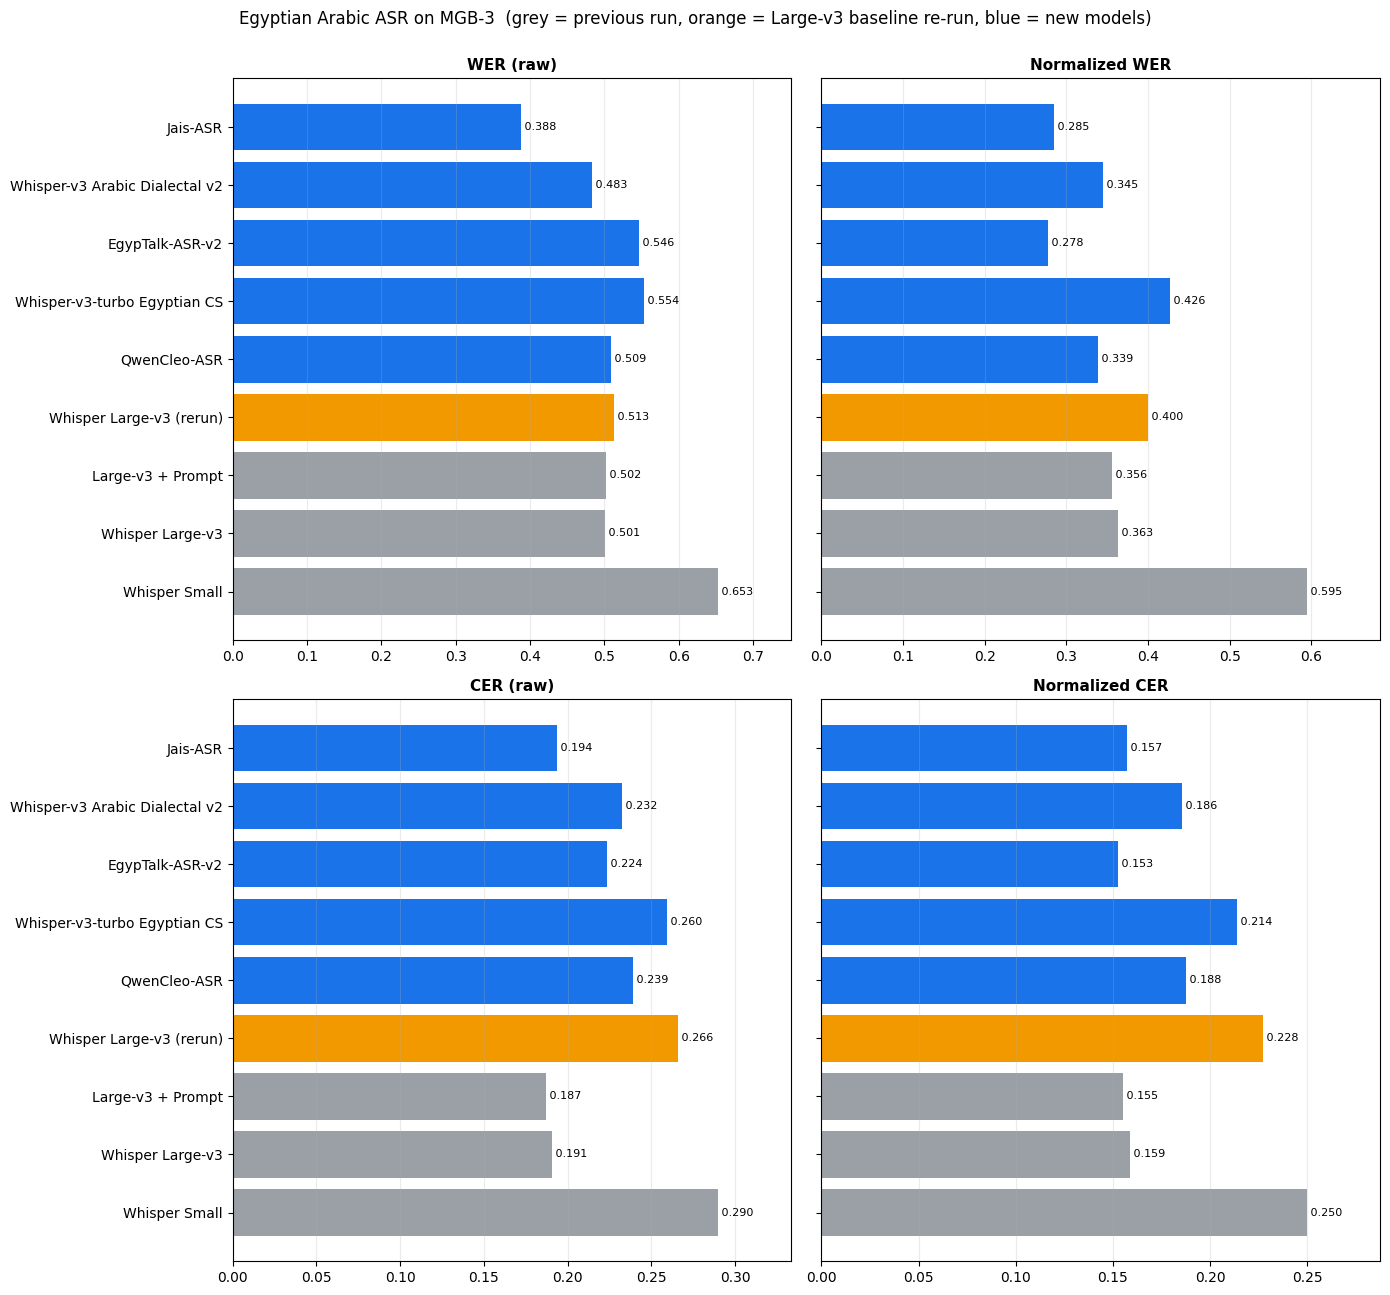

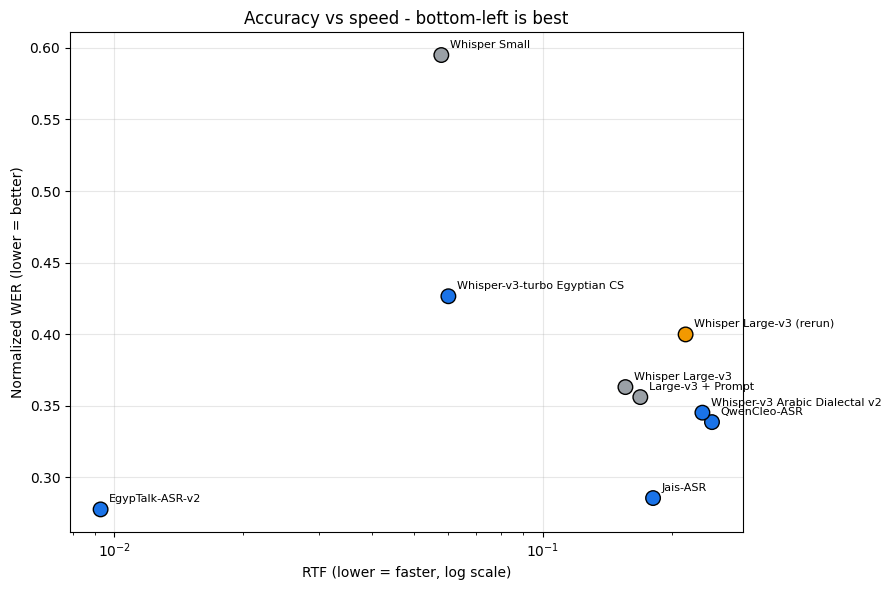

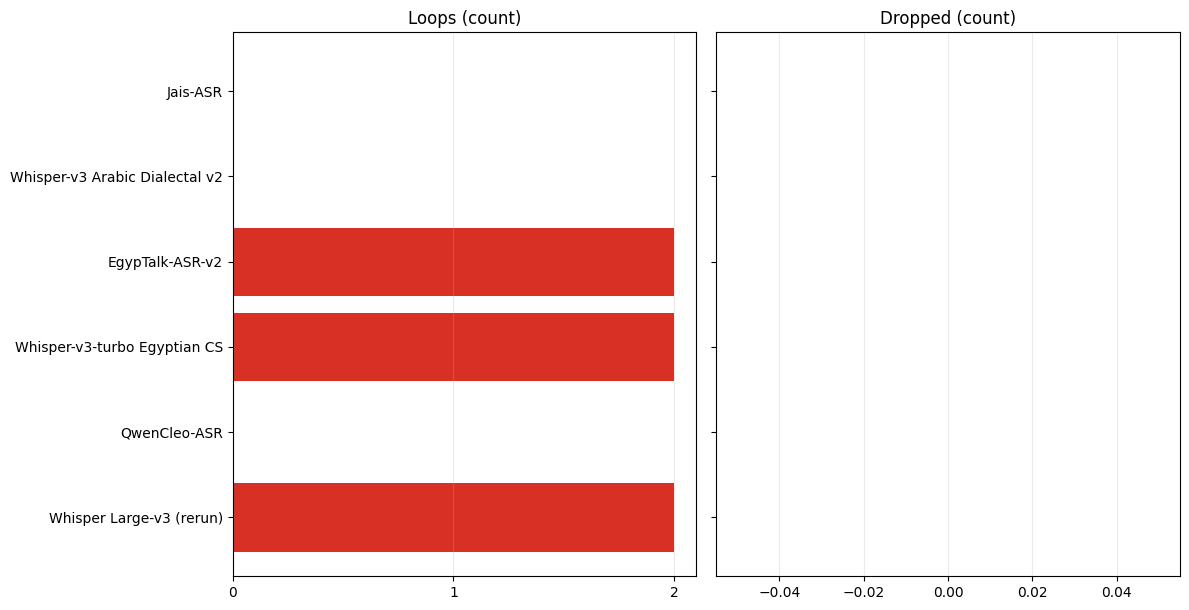

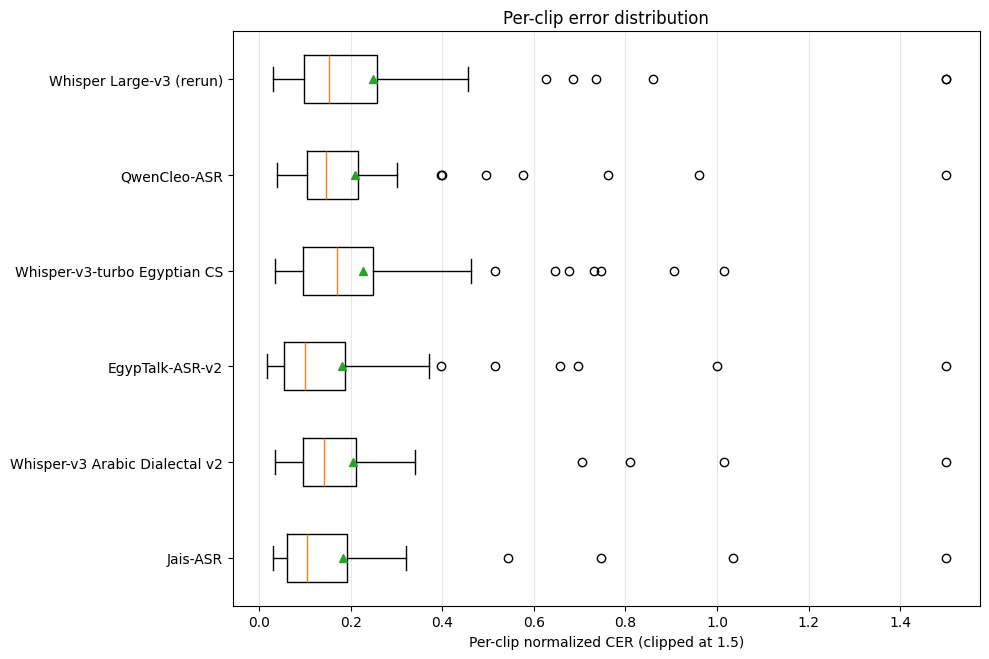

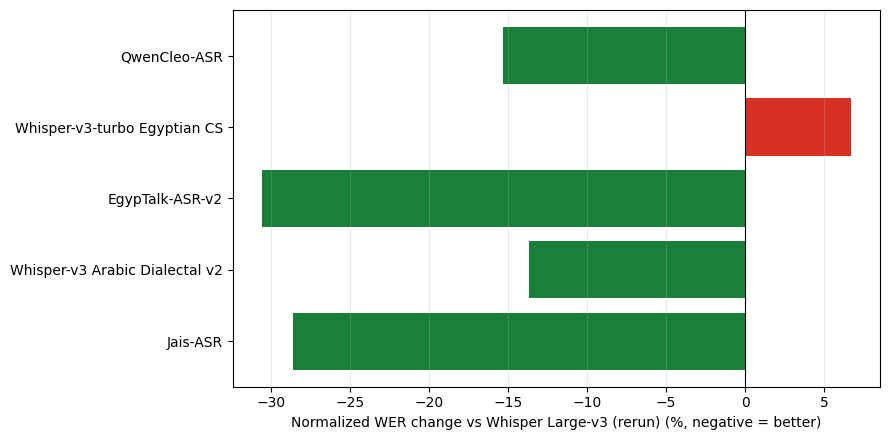

In [19]:
def make_plots():
    order = FINAL["Model"].tolist()
    colors = ["#9aa0a6" if s == "previous" else "#1a73e8" for s in FINAL["Source"]]
    for i, m in enumerate(order):
        if m == BASELINE_LABEL: colors[i] = "#f29900"

    def hbar(ax, col, title, fmt="{:.3f}"):
        vals = FINAL[col].values
        bars = ax.barh(order, vals, color=colors)
        ax.invert_yaxis(); ax.set_title(title, fontsize=11, weight="bold")
        for b, v in zip(bars, vals):
            if pd.notna(v): ax.text(b.get_width(), b.get_y() + b.get_height()/2, " " + fmt.format(v), va="center", fontsize=8)
        ax.margins(x=0.15); ax.grid(axis="x", alpha=0.25)

    # 1) accuracy: four error metrics
    fig, axes = plt.subplots(2, 2, figsize=(14, 3 + 0.55 * len(order) * 2), sharey=True)
    for ax, (col, title) in zip(axes.ravel(), [("WER", "WER (raw)"), ("Norm WER", "Normalized WER"),
                                               ("CER", "CER (raw)"), ("Norm CER", "Normalized CER")]):
        hbar(ax, col, title)
    fig.suptitle("Egyptian Arabic ASR on MGB-3  (grey = previous run, orange = Large-v3 baseline re-run, blue = new models)", y=1.0)
    fig.tight_layout(); fig.savefig(FIG_DIR / "accuracy_metrics.png", dpi=150, bbox_inches="tight"); plt.show()

    # 2) speed vs accuracy
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(FINAL["RTF"], FINAL["Norm WER"], c=colors, s=110, edgecolor="k", zorder=3)
    for _, r in FINAL.iterrows():
        ax.annotate(r["Model"], (r["RTF"], r["Norm WER"]), textcoords="offset points", xytext=(6, 5), fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel("RTF (lower = faster, log scale)"); ax.set_ylabel("Normalized WER (lower = better)")
    ax.set_title("Accuracy vs speed - bottom-left is best"); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(FIG_DIR / "speed_vs_accuracy.png", dpi=150); plt.show()

    # 3) reliability: loops and dropped segments (this run only)
    if len(NEW):
        fig, axes = plt.subplots(1, 2, figsize=(12, 0.7 * len(NEW) + 2), sharey=True)
        for ax, col in zip(axes, ["Loops", "Dropped"]):
            ax.barh(NEW["Model"], NEW[col], color="#d93025"); ax.invert_yaxis(); ax.set_title(f"{col} (count)")
            ax.xaxis.get_major_locator().set_params(integer=True); ax.grid(axis="x", alpha=0.25)
        fig.tight_layout(); fig.savefig(FIG_DIR / "loops_dropped.png", dpi=150); plt.show()

    # 4) per-clip normalized CER distribution
    if CLIP_SCORES:
        fig, ax = plt.subplots(figsize=(10, 0.7 * len(CLIP_SCORES) + 2.5))
        labels = list(CLIP_SCORES)
        ax.boxplot([CLIP_SCORES[l]["norm_cer"].clip(upper=1.5) for l in labels], vert=False, showmeans=True)
        ax.set_yticklabels(labels)
        ax.invert_yaxis(); ax.set_xlabel("Per-clip normalized CER (clipped at 1.5)"); ax.grid(axis="x", alpha=0.3)
        ax.set_title("Per-clip error distribution")
        fig.tight_layout(); fig.savefig(FIG_DIR / "clip_cer_distribution.png", dpi=150); plt.show()

    # 5) change vs baseline
    delta = FINAL[(FINAL["Model"] != base_label) & (FINAL["Source"] == "this run")]
    if len(delta):
        fig, ax = plt.subplots(figsize=(9, 0.5 * len(delta) + 2))
        ax.barh(delta["Model"], delta["Norm WER rel. %"], color=["#188038" if v < 0 else "#d93025" for v in delta["Norm WER rel. %"]])
        ax.invert_yaxis(); ax.axvline(0, color="k", lw=0.8); ax.grid(axis="x", alpha=0.25)
        ax.set_xlabel(f"Normalized WER change vs {base_label} (%, negative = better)")
        fig.tight_layout(); fig.savefig(FIG_DIR / "delta_vs_baseline.png", dpi=150); plt.show()

if len(NEW):
    make_plots()
else:
    print("Nothing to plot yet - run at least one model cell in section 10.")

## 13. Per-clip analysis and error breakdown

Aggregate scores can hide important failure patterns. This section examines performance at clip level by reporting:

- The substitution, deletion, and insertion components of normalized WER.
- The number of clips each model scores better than, equal to, or worse than the baseline.
- The most difficult clips for the best-ranked newly evaluated model.
- Side-by-side reference and hypothesis transcripts.
- Clips flagged for repeated-output loops or dropped predictions.

Use these examples to understand *how* models fail, not only how their average scores compare.

In [20]:
if CLIP_SCORES:
    bd = []
    for lab, d in CLIP_SCORES.items():
        r = jiwer.process_words(list(d["ref_norm"]), [_fix(h) for h in d["hyp_norm"]])
        N = r.hits + r.substitutions + r.deletions
        bd.append({"Model": lab, "Ref words": N, "Substitution %": 100 * r.substitutions / N,
                   "Deletion %": 100 * r.deletions / N, "Insertion %": 100 * r.insertions / N, "WER %": 100 * r.wer})
    print("Normalized WER breakdown:")
    display(pd.DataFrame(bd).round(2))

if BASELINE_LABEL in CLIP_SCORES and len(CLIP_SCORES) > 1:
    b = CLIP_SCORES[BASELINE_LABEL].set_index("idx")["norm_cer"]
    wl = []
    for lab, d in CLIP_SCORES.items():
        if lab == BASELINE_LABEL: continue
        c = d.set_index("idx")["norm_cer"]
        wl.append({"Model": lab, "better than baseline (clips)": int((c < b - 1e-9).sum()),
                   "tied": int(((c - b).abs() <= 1e-9).sum()), "worse (clips)": int((c > b + 1e-9).sum())})
    print("\nPer-clip normalized CER vs baseline:")
    display(pd.DataFrame(wl))

if len(RANKED):
    best = RANKED.iloc[0]["Model"]
    print(f"\nHardest clips for the best new model: {best}")
    display(CLIP_SCORES[best].sort_values("norm_cer", ascending=False)
            [["idx", "duration_sec", "norm_cer", "ref_raw", "hyp_raw", "error"]].head(15))

    print("\nSide-by-side (normalized) for the first 8 clips:")
    side = pd.DataFrame({"reference": CLIP_SCORES[best].set_index("idx")["ref_norm"]})
    for lab, d in CLIP_SCORES.items():
        side[lab] = d.set_index("idx")["hyp_norm"]
    with pd.option_context("display.max_colwidth", 80, "display.width", 250):
        display(side.head(8))

    flagged = pd.concat([d.assign(model=lab)[d["loop"] | d["dropped"]] for lab, d in CLIP_SCORES.items()])
    if len(flagged):
        print("\nClips flagged as loop or dropped:")
        display(flagged[["model", "idx", "loop", "dropped", "error", "ref_raw", "hyp_raw"]])

Normalized WER breakdown:


,Model,Ref words,Substitution %,Deletion %,Insertion %,WER %
0,Whisper Large-v3 (rerun),3787,21.55,12.41,6.02,39.98
1,QwenCleo-ASR,3787,19.73,8.34,5.78,33.85
2,Whisper-v3-turbo Egyptian CS,3787,25.24,11.65,5.76,42.65
3,EgypTalk-ASR-v2,3787,14.44,6.55,6.76,27.75
4,Whisper-v3 Arabic Dialectal v2,3787,20.15,7.60,6.76,34.51
5,Jais-ASR,3787,15.50,7.68,5.36,28.55



Per-clip normalized CER vs baseline:


,Model,better than baseline (clips),tied,worse (clips)
0,QwenCleo-ASR,36,1,23
1,Whisper-v3-turbo Egyptian CS,29,2,29
2,EgypTalk-ASR-v2,50,1,9
3,Whisper-v3 Arabic Dialectal v2,38,2,20
4,Jais-ASR,43,5,12



Hardest clips for the best new model: EgypTalk-ASR-v2


,idx,duration_sec,norm_cer,ref_raw,hyp_raw,error
36,36,30.080,1.991525,لا أن تتوقف أرحب بضيوفنا الكرام أرحب بالدكتور ...,لا ان تتوقف ارحب بضيوفنا الكرام ارحب بالدكتور ...,
49,49,28.928,1.000000,مبيلبسوش مبيخرجوش مبيعملوش أي حاجة لمجرد إن هم...,بشوفها ما بيلبسوش ما بيخرجوش ما بيعملوش اي حاج...,
12,12,28.032,0.695876,تمام ... بي بيبدأ مرحلة العند وهو عنده شهور يع...,تمام ا بيبدا مرحله العند ا وعنده شهور يعني هو ...,
33,33,8.960,0.657658,أنا بالنسبة لهم زبون مثالي جداً أبقى خارج من ا...,هو ايه الميكروباص انا بالنسبه لنا مزبوط مثالي ...,
15,15,28.928,0.515337,نختار منهم اللي تبقي ملكة جمال مصر ... حلو ......,مصر نختار منهم اللي تبقي ملكه جمال مصر لان في ...,
7,7,19.968,0.396226,وي وي ويتفاعل معاه وعنده مشاكل ويحلها الطفل بي...,وي وي وي وي وي وي وي وي وي وي وي وي وي وي وي و...,
56,56,29.056,0.370098,عايز جينز مقاسك يا باشا أول ما شافني وعليكم ال...,عايز جنس مقاسك كمان اول ما شاف وعالف ساعه بركا...,
13,13,8.064,0.308411,وهتقعد ف ف ف هنا ف الأوضة دي أو ... و دلوقتي ا...,وهتقعد في في هنا في ال في الاوضه دي او ودلوقتي...,
43,43,28.032,0.273756,هلبس اللي أنا عايزاه ... مش هيبقى يعني غلط قوي...,حلو هلبس اللي انا عايزاه ايوه يعني بتلبس حاجه ...,
53,53,23.936,0.265092,لا هو يعني بالنسبة لل (detectorsوالحاجات دي ف ...,لا هو يعني بالنسبه للديكترز والحاجات دي تبقي ص...,



Side-by-side (normalized) for the first 8 clips:


,reference,Whisper Large-v3 (rerun),QwenCleo-ASR,Whisper-v3-turbo Egyptian CS,EgypTalk-ASR-v2,Whisper-v3 Arabic Dialectal v2,Jais-ASR
idx,,,,,,,
0,انه هو مع البدايه ان just انه هي في بطنها ان هي سعيده ف بتغنيله غير ان الام ...,انه هو مع البدايه النجاست انه هي ببطنها فهي سعيده فبتغني له غير ان الام دي ل...,ان هو مع البدايه ان جاست ان هي يبطلها فهي سعيده فبتغني له غير ان الام دي لا ...,ان هو مع البدايه النجاسه ان هي بطنها فهي سعيده فبتغنيله غير ان الام دي لقدر ...,ان هو مع البدايه ان جست ان هي في بطنها فهي سعيده فبتغني له غير ان الام دي لا...,انه هو مع البدايه النجاست انه هي ببطنها فهي سعيده فبتغني له امم غير ان الام ...,انه هو مع البدايه ان جاست انها بطنها فهي سعيده فبتغني له غير ان الام دي لا ق...
1,هتلاقي الشيب بتاع جسمها مثلا اس او ميديم وتقولك في موجود اتنين اكس لارج فانا...,هتلاقي الشي بتاع جسمها مثلا اه او وتقول لك في موجود اتنين اكس لوج فانا بالنس...,لوش مثلا هتلاقي الشب بتاع الجسمها مثلا s او medium وتقولك فيه موجود 2x large...,هتلاقي الشاب بتاع جسمها مثلا اس او ميديم و تقولك في موجود اتنين اكس لوج فانا...,هتلاقي الشاب بتاع جسمها مثلا اس او ميديم وتقول لك في موجود اتنين اكسلاوج فان...,لوج مثلا هتلاقي الشي بتاع جسمها مثلا اس او ميديم وتقول لك في موجود اتنين اكس...,لوج مثلا هتلاقي الشيب بتاع جسمها مثلا اس او ميديوم وتقولك في موجود اتنين اكس...
2,دي عباره عن معدن في منها حلل عباره عن معدن مطلي بطبقه عازله طول ما هو الطبقه...,صاج دي عباره عن معدن في منحلا عباره عن معدن اه مطن بطبقه عزله طول ما هو الطب...,ده عباره عن معدن فيه منها حلقه عباره عن معدن مطلي بطبقه عازله طول ما هو الطب...,دي عباره عن معدن في مناح حلل عباره عن معدن مطلب طبقه قازله طول ما هو الطبقه ...,دي عباره عن معدن في منها حلل عباره عن معدن ا مطني بطبقه عازله طول ما هو الطب...,مصج دي عباره عن معدن في منع حلان عباره عن معدن مطلي بطبقه عزله طول ما هو الط...,دي عباره عن معدن في منها حلو عباره عن معدن مطلي بطبقه عازله طول ما هو الطبقه...
3,ال الدنيا هناك عامله ازاي يعني بس طب دكتور عمرو خلينا نتكلم عن اهميه الزياره...,الدنيا هناك عامله زي يعني بس طب دكتور عمر خلينا نتكلم عن اهميه الزياره دي وا...,الدنيا هناك عامله ازاي يعني بس طب دكتور عمرو خلينا نتكلم عن اهميه الزياره دي...,الدنيا هناك عامله ازاي يعني بس طب دكتور عمر خلينا نتكلم عن اهميه الزياره دي ...,ال الدنيا هناك عامله ازاي يعني بس طب دكتور عمرو خلينا نتكلم عن اهميه الزياره...,ال الدنيا هناك عامله ازاي يعني بس طب دكتور عمرو خلينا نتكلم عن اهميه الزياره...,الدوني هناك عامله ازاي يعني بس طب دكتور عمرو خلينا نتكلم عن اهميه الزياره دي...
4,احب انوه برضو علشان ان هو دي مش مش اخر زياره لسيرن مركز الفيزياء الاساسيه يع...,احب ان اوه برضو علشان ان هو دي مش اخر زياره لسيرن مركز الفيزياء الاساسيه يعن...,احب انوي برضه علشان ان هو دي مش مش اخر زياره للسيرن مركز الفيزياء الاساسيه ي...,احب ان اقول برضه علشان ان هو دي مش اخر زياره لسرن مركز الفيزييات الاساسيه يع...,احب انوه برضه علشان ان هو دي مش مش اخر زياره لسير ا مركز الفيزياء الاساسيه ا...,احب اناوه برضه علشان ان هو دي مش مش اخر زياره لسيرن مركز الفيزياء الاساسيه ا...,احب انوه برضو علشان ان هو دي مش مش اخر زياره لسيرن مركز الفيزياء الاساسيه يع...
5,ا نظرا لان البنت من بعد سن البلوغ تتعرض ف حياتها ا لضغوط وتغيرات هرمونيه وتغ...,اكثر نظرا لان البنت من بعد سن البلوغ تتعرض في حياتها لضغوط وتغيرات هرمونيه و...,اكتر نظرا لان البنت من بعد سن البلوغ تتعرض في حياتها لضغوط وتغيرات هرمونيه و...,اكتر نظرا لان البنت من بعد سن البلوغ تتعرض في حياتها لضغوط و تغيرات هرمونيه ...,اكتر ا نظرا لان البنت من بعد سن البلوغ تتعرض في حياتها ا لضغوط وتغيرات هرمون...,اكتر نظرا لان البنت من بعد سن البلوغ تتعرض في حياتها لضغوط وتغيرات هرمونيه و...,اكتر نظرا لان البنت من بعد سن البلوغ تتعرض في حياتها لضغوط وتغيرات هرمونيه و...
6,شويه ان ان الانفصال ده بيبقي علي الطرفين بيبقي علي الام وبيبقي علي الطفل صحي...,شويه الانفصال ده بيبقي علي الطرفين بيبقي علي الام وبيبقي علي الطفل صحيح لكن ...,شويه ان الانفصال ده بيبقي علي الطرفين بيبقي علي الام وبيبقي علي الطفل صحيح ل...,شويه ان الانفصال ده بيبقي علي الطرفين بيبقي علي الام و بيبقي علي الطفل لكن ب...,شويه ان ان الانفصال ده بيبقي علي الطرفين بيبقي علي الام وبيبقي علي الطفل صحي...,شويه ان ان الانفصال دا بيبقي ع الطرفين بيبقي علي الام و بيبقي علي الطفل صحيح...,ش


Clips flagged as loop or dropped:


,model,idx,loop,dropped,error,ref_raw,hyp_raw
33,Whisper Large-v3 (rerun),33,True,False,,أنا بالنسبة لهم زبون مثالي جداً أبقى خارج من ا...,انا بالنسبة لهم زبون مثالي جدا انا باخرج من ال...
43,Whisper Large-v3 (rerun),43,True,False,,هلبس اللي أنا عايزاه ... مش هيبقى يعني غلط قوي...,حلو حلبس اللي انا عايزاها حلو كار حلو كار لونك...
15,Whisper-v3-turbo Egyptian CS,15,True,False,,نختار منهم اللي تبقي ملكة جمال مصر ... حلو ......,مصر نختار منهم اللي تبقى مالك الجمال مصر لان ف...
40,Whisper-v3-turbo Egyptian CS,40,True,False,,دكتور محمد لو سمحت أنا متجوزة بقالي تلات شهور ...,انا انا اتفعيه ده ده ده ده ده ده ده ده ده ده د...
4,EgypTalk-ASR-v2,4,True,False,,أحب أنوه برضو علشان إن هو دي مش مش آخر زيارة ل...,احب انوه برضه علشان ان هو دي مش مش اخر زياره ل...
7,EgypTalk-ASR-v2,7,True,False,,وي وي ويتفاعل معاه وعنده مشاكل ويحلها الطفل بي...,وي وي وي وي وي وي وي وي وي وي وي وي وي وي وي و...


## 14. Export benchmark artifacts

The notebook saves the comparison results, clip-level predictions and metrics, cached audio, logs, and generated figures under the configured output directory.

| Artifact | Description |
|---|---|
| `predictions/*.jsonl` | Per-clip model predictions, inference time, and error information |
| `data_cache/*.pkl` | Cached preprocessed audio clips |
| `final_results.csv` | Previous and current benchmark results, including baseline deltas |
| `clip_level_results.csv` | Reference/prediction pairs and per-clip metrics |
| `logs/*.log` | Isolated-worker logs for debugging |
| `figures/*.png` | Generated benchmark visualizations |

In [21]:
FINAL.to_csv(OUT_DIR / "final_results.csv", index=False)
if CLIP_SCORES:
    pd.concat([d.assign(model=lab) for lab, d in CLIP_SCORES.items()]).to_csv(
        OUT_DIR / "clip_level_results.csv", index=False, encoding="utf-8-sig")

print("Saved to", OUT_DIR.resolve())
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and "workers" not in p.parts:
        print(f"  {p.relative_to(OUT_DIR)}  ({p.stat().st_size/1024:.0f} KB)")

Saved to /content/asr_benchmark_outputs
  clip_level_results.csv  (842 KB)
  data_cache/MGB3_n60_s42_b500.pkl  (95248 KB)
  figures/accuracy_metrics.png  (177 KB)
  figures/clip_cer_distribution.png  (64 KB)
  figures/delta_vs_baseline.png  (45 KB)
  figures/loops_dropped.png  (49 KB)
  figures/speed_vs_accuracy.png  (78 KB)
  final_results.csv  (2 KB)
  logs/EgypTalk-ASR-v2.log  (37 KB)
  logs/Jais-ASR.log  (3 KB)
  logs/QwenCleo-ASR.log  (5 KB)
  predictions/EgypTalk-ASR-v2__0bf55703.jsonl  (38 KB)
  predictions/Jais-ASR__2bd5acf2.jsonl  (42 KB)
  predictions/QwenCleo-ASR__c5c2cd2d.jsonl  (37 KB)
  predictions/Whisper-v3-turbo_Egyptian_CS__c0509d2b.jsonl  (36 KB)
  predictions/Whisper-v3_Arabic_Dialectal_v2__8b712146.jsonl  (39 KB)
  predictions/Whisper_Large-v3_rerun__4316f4a0.jsonl  (37 KB)
  previous_results.csv  (0 KB)


## 15. Optional: transcribe a single audio file

Use this section to test one audio file with any configured model without running the full benchmark. In Colab, upload the file or provide a valid file path, then call `quick_test("<model_id>", path, reference="...")`.

For longer recordings, increase `max_new_tokens` as needed. Single-file tests are not added to the benchmark cache or comparison tables.

In [22]:
def quick_test(model_id, audio_path, reference=None, max_new_tokens=None):
    import soundfile as sf
    audio, sr = sf.read(audio_path, dtype="float32")
    if audio.ndim == 2: audio = audio.mean(axis=1)
    if sr != 16000:
        g = gcd(int(sr), 16000); audio = resample_poly(audio, 16000 // g, int(sr) // g)
    audio = np.clip(np.nan_to_num(audio), -1, 1).astype(np.float32)
    dur = len(audio) / 16000

    spec = dict(SPEC_BY_ID[model_id])
    if max_new_tokens: spec["max_new_tokens"] = max_new_tokens
    backend = make_backend(spec)
    try:
        backend.load()
        gpu_sync(); t = time.perf_counter()
        text = backend.transcribe(audio)
        gpu_sync(); dt = getattr(backend, "last_infer_sec", None) or (time.perf_counter() - t)
        meta = getattr(backend, "last_meta", None)
    finally:
        backend.unload(); free_gpu()

    print(f"{spec['label']} | {dur:.1f}s audio | {dt:.2f}s inference | RTF {dt/dur:.3f}" + (f" | {meta}" if meta else ""))
    print("Prediction:", text)
    if reference:
        print("Reference: ", reference)
        print(f"Norm WER {clip_wer(normalize_ar(reference), normalize_ar(text)):.3f} | "
              f"Norm CER {clip_cer(normalize_ar(reference), normalize_ar(text)):.3f}")

# from google.colab import files; up = files.upload(); path = next(iter(up))
# quick_test("jais", path, reference="النص الصحيح هنا", max_new_tokens=448)

## Interpreting the results and limitations

1. **Keep the evaluation set in mind.** These scores describe only the selected MGB-3 clips; results from different datasets, splits, or sample sizes are not directly comparable.
2. **Check for possible training overlap.** MGB-3 is public data. Verify each model's training data and evaluate on independent Egyptian Arabic recordings before drawing conclusions about generalization.
3. **Read reliability metrics alongside accuracy.** Review `Loops` and `Dropped` before trusting a low WER. A model that fails to produce usable transcripts for difficult clips may appear better if those failures are overlooked.
4. **Interpret RTF in context.** It measures batch-size-one inference latency on this runtime and hardware; it is not a measure of long-audio throughput or production serving capacity.
5. **Account for normalization choices.** Arabic spelling and orthographic variation can affect WER/CER. Compare raw and normalized metrics and inspect sample transcripts rather than relying on one score.
6. **Treat the benchmark as a controlled experiment, not a universal leaderboard.** Model revisions, dependency versions, hardware, decoding behavior, and dataset composition can all affect results.

For a stronger follow-up evaluation, use a held-out set of Egyptian Arabic recordings that is independent of the models' training data, and document the dataset version, hardware, and model revisions alongside the scores.